# GEOM90006 Group 15 — Formative Task

**Authors:** Balqes Mahdi M Alatawi, Xianglong Fu, Chang Gu

## Project Title
Tracks, Tickets and Territories: A Spatially Heterogeneous Analysis of Train Accessibility, House Prices and Population Characteristics in Greater Melbourne

## Research Question

In direct response to our second research question — where does poor train accessibility coincide with markers of socio-economic disadvantage ("transit deserts") — this map identifies potential transit deserts in Greater Melbourne.

**Dependencies:** Requires `contextily`, `matplotlib-scalebar`, `mapclassify` in addition to the `spanalytics` conda environment. 

Install with: `pip install contextily matplotlib-scalebar mapclassify`

stations loaded: 226
transit desert suburbs: 45
low income threshold: $743/week
poor access threshold: 11.3 km


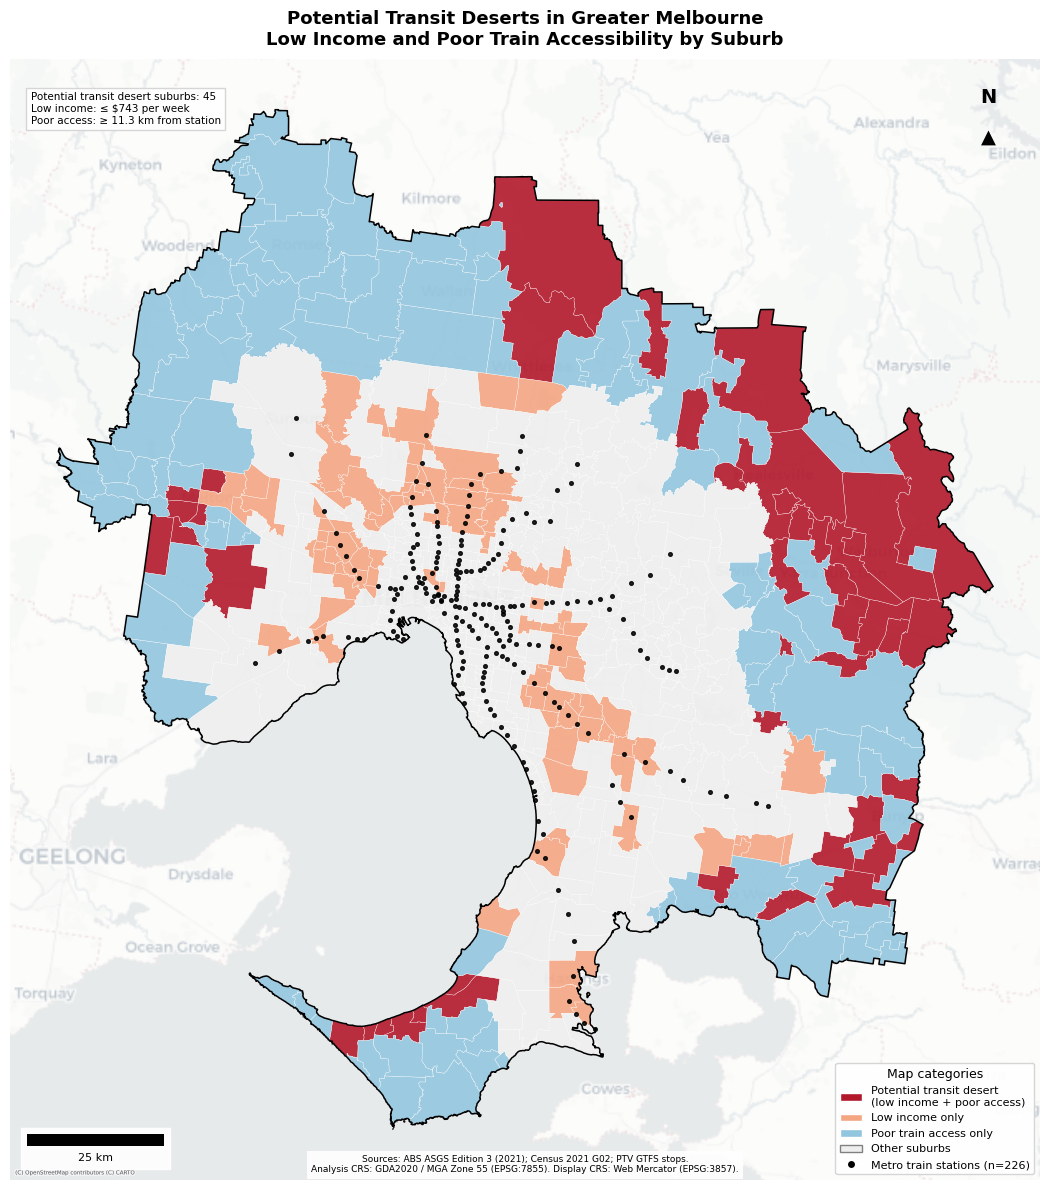

In [13]:
from pathlib import Path
import zipfile, io
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import contextily as ctx
from matplotlib_scalebar.scalebar import ScaleBar
import numpy as np
from shapely.ops import nearest_points
import warnings
warnings.filterwarnings('ignore')

# ==============================================
# STEP 1: Set up paths
# ==============================================

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent

ASG  = REPO / "assignment_data"
PROC = REPO / "data" / "processed"

# ==============================================
# STEP 2: Load data
# ==============================================

# boundaries
melbourne = gpd.read_file(ASG / "Greater Melbourne (ABS) study area.shp")
census = gpd.read_file(ASG / "Census 2021 table G02 Victoria.gpkg")

# train stations from GTFS zip
gtfs_zip = PROC / "gtfs_metro_train.zip"
with zipfile.ZipFile(gtfs_zip) as outer:
    inner_name = next(n for n in outer.namelist()
                      if n.startswith("2/") and n.endswith(".zip"))
    with outer.open(inner_name) as f:
        with zipfile.ZipFile(io.BytesIO(f.read())) as inner:
            stops = pd.read_csv(inner.open("stops.txt"))

# reproject to working CRS
melbourne = melbourne.to_crs(7855)
census = census.to_crs(7855)

# clip suburbs to greater melbourne
census_melb = gpd.clip(census, melbourne).copy()

# ==============================================
# STEP 3: Prepare income indicator
# ==============================================

income_col = 'Median_tot_prsnl_inc_weekly'
census_melb[income_col] = pd.to_numeric(census_melb[income_col], errors='coerce')
# replace 0 with NaN
census_melb['income_for_analysis'] = census_melb[income_col].replace(0, np.nan)

# ==============================================
# STEP 4: Prepare train stations
# ==============================================

# keep parent stations only (one point per station)
stations_unique = stops[stops['location_type'] == 1].copy()

stations_gdf = gpd.GeoDataFrame(
    stations_unique,
    geometry=gpd.points_from_xy(stations_unique['stop_lon'], stations_unique['stop_lat']),
    crs='EPSG:4326'
).to_crs(7855)

# clip to greater melbourne
stations_gdf = gpd.clip(stations_gdf, melbourne)
print(f'stations loaded: {len(stations_gdf)}')

# ==============================================
# STEP 5: Calculate distance to nearest station
# ==============================================

# get centroid of each suburb
census_centroids = census_melb.copy()
census_centroids['geometry'] = census_centroids.geometry.centroid
station_union = stations_gdf.geometry.unary_union

# distance from each suburb centroid to nearest station
census_melb['dist_nearest_station_m'] = census_centroids.geometry.apply(
    lambda point: point.distance(nearest_points(point, station_union)[1])
)
census_melb['dist_nearest_station_km'] = census_melb['dist_nearest_station_m'] / 1000

# ==============================================
# STEP 6: Classify transit deserts
# ==============================================

# bottom 25% income = low income
income_threshold = census_melb['income_for_analysis'].quantile(0.25)
# top 25% distance = poor access
distance_threshold = census_melb['dist_nearest_station_km'].quantile(0.75)

census_melb['low_income'] = census_melb['income_for_analysis'] <= income_threshold
census_melb['poor_train_access'] = census_melb['dist_nearest_station_km'] >= distance_threshold
# transit desert = both conditions together
census_melb['potential_transit_desert'] = census_melb['low_income'] & census_melb['poor_train_access']

def classify_suburb(row):
    if row['potential_transit_desert']:
        return 'Potential transit desert'
    elif row['low_income']:
        return 'Low income only'
    elif row['poor_train_access']:
        return 'Poor train access only'
    else:
        return 'Other suburbs'

census_melb['access_income_category'] = census_melb.apply(classify_suburb, axis=1)

print(f'transit desert suburbs: {census_melb["potential_transit_desert"].sum()}')
print(f'low income threshold: ${income_threshold:,.0f}/week')
print(f'poor access threshold: {distance_threshold:.1f} km')

# ==============================================
# STEP 7: Plot map
# ==============================================

# reproject to web mercator for basemap
melbourne_3857 = melbourne.to_crs(3857)
census_3857 = census_melb.to_crs(3857)
stations_3857 = stations_gdf.to_crs(3857)

category_colours = {
    'Potential transit desert': '#b2182b',
    'Low income only':          '#f4a582',
    'Poor train access only':   '#92c5de',
    'Other suburbs':            '#eeeeee'
}

fig, ax = plt.subplots(figsize=(12, 12))

# plot each category
for category, colour in category_colours.items():
    census_3857[census_3857['access_income_category'] == category].plot(
        ax=ax, color=colour, edgecolor='white', linewidth=0.25, alpha=0.9, zorder=2
    )

# study area boundary
melbourne_3857.boundary.plot(ax=ax, color='black', linewidth=1.1, zorder=5)

# train stations
stations_3857.plot(ax=ax, color='black', markersize=7, marker='o', alpha=0.85, zorder=6)

# basemap
ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron, alpha=0.55, attribution_size=5)

# shrink carto text
for child in ax.get_children():
    if hasattr(child, 'get_text'):
        if 'CARTO' in str(child.get_text()) or 'OpenStreetMap' in str(child.get_text()):
            child.set_fontsize(4)
            child.set_alpha(0.5)

# title
ax.set_title(
    'Potential Transit Deserts in Greater Melbourne\n'
    'Low Income and Poor Train Accessibility by Suburb',
    fontsize=13, fontweight='bold', pad=10
)

# legend
legend_elements = [
    mpatches.Patch(facecolor='#b2182b', edgecolor='white',
                   label='Potential transit desert\n(low income + poor access)'),
    mpatches.Patch(facecolor='#f4a582', edgecolor='white', label='Low income only'),
    mpatches.Patch(facecolor='#92c5de', edgecolor='white', label='Poor train access only'),
    mpatches.Patch(facecolor='#eeeeee', edgecolor='grey', label='Other suburbs'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black',
               markersize=6, label=f'Metro train stations (n={len(stations_gdf)})')
]

legend = ax.legend(handles=legend_elements, loc='lower right', fontsize=8,
                   framealpha=0.95, title='Map categories', title_fontsize=9)
legend.get_frame().set_facecolor('white')
legend.get_frame().set_edgecolor('lightgrey')

# north arrow - top right
ax.annotate('N', xy=(0.95, 0.965), xycoords='axes fraction',
            fontsize=14, fontweight='bold', ha='center', va='center', zorder=20)
ax.annotate('▲', xy=(0.95, 0.93), xycoords='axes fraction',
            fontsize=14, ha='center', va='center', zorder=20)

# scale bar - bottom left
ax.add_artist(ScaleBar(dx=1, units='m', location='lower left',
                       length_fraction=0.18, font_properties={'size': 8},
                       frameon=True, box_alpha=0.9, scale_loc='bottom',
                       pad=0.45, border_pad=0.8))

# stats box - top left
ax.text(0.02, 0.97,
        f'Potential transit desert suburbs: {census_melb["potential_transit_desert"].sum()}\n'
        f'Low income: ≤ ${income_threshold:,.0f} per week\n'
        f'Poor access: ≥ {distance_threshold:.1f} km from station',
        transform=ax.transAxes, fontsize=7.5, verticalalignment='top',
        horizontalalignment='left',
        bbox=dict(facecolor='white', alpha=0.92, edgecolor='lightgrey', pad=3), zorder=15)

# source note - bottom centre
ax.text(0.5, 0.005,
        'Sources: ABS ASGS Edition 3 (2021); Census 2021 G02; PTV GTFS stops.\n'
        'Analysis CRS: GDA2020 / MGA Zone 55 (EPSG:7855). Display CRS: Web Mercator (EPSG:3857).',
        transform=ax.transAxes, fontsize=6.5, verticalalignment='bottom',
        horizontalalignment='center',
        bbox=dict(facecolor='white', alpha=0.88, edgecolor='none', pad=3), zorder=15)

ax.set_axis_off()
plt.tight_layout()
plt.savefig(REPO / 'notebooks/formative_transit_deserts.png', dpi=300, bbox_inches='tight')
plt.savefig(REPO / 'notebooks/formative_transit_deserts.pdf', dpi=300, bbox_inches='tight')
plt.show()

### Interpretation

This map identifies potential transit deserts in Greater Melbourne by combining two indicators: median weekly personal income and distance to the nearest metro train station. Suburbs shown in red represent areas that fall within the lowest 25% of income and the highest 25% of distance from a train station. These suburbs are therefore classified as potential transit deserts because they combine socio-economic disadvantage with weaker rail accessibility.

The map suggests that potential transit deserts are not randomly distributed. Many appear in outer or edge areas of Greater Melbourne, especially where train stations are sparse. In contrast, inner and middle suburbs tend to have stronger station coverage, even where some low-income areas are present. This pattern is important because limited train access may increase dependence on cars or longer travel times, which can create additional pressure for lower-income communities. Overall, the map provides an early spatial basis for investigating transport equity. 

However, two limitations should be noted: the centroid-to-station distance metric may overstate inaccessibility in large outer suburbs where residents do not actually live near the centroid, and income alone is only a partial proxy for socio-economic disadvantage. The main project will refine this with population-weighted accessibility and bivariate LISA clustering to avoid arbitrary thresholds.